# 02 - Metode Pembanding: Fitur Spektral, DenseNet121, dan Attention

Tujuan notebook ini adalah **mengungguli MosquitoSong+** (resep penulis, 1000 epoch) pada split, augmentasi, validation, dan test set yang sama. Pembanding raw waveform dari run pertama (VoVNet-eSE, ECAPA raw, Conv-Transformer) tertinggal dari MosquitoSong+ di validation sehingga tidak dilanjutkan. Set final memakai **fitur spektral**, karena EDA (notebook 01 bagian 5) menunjukkan F0 kelas yang sering tertukar saling tumpang tindih dan > 70 % energi sinyal berupa rumble < 60 Hz yang tidak membawa informasi kelas.

| Metode | Input | Resep | Hipotesis | Parameter |
|---|---|---|---|---|
| MosquitoSong+ (baseline, dari notebook 01) | raw waveform | paper: Adam 1e-4, 1000 epoch | acuan H2-H4 | 349 k |
| MFCC-CNN | MFCC 30 frame × 40 koefisien | cepat: Adam + cosine, ≤ 100 epoch, patience 20; lr 1e-3 / 3e-4 | H2 | 113 k |
| ECAPA-MFCC | MFCC 30 × 40 | cepat; lr 1e-3 / 3e-4 | H2 | 366 k |
| DenseNet121-spektrogram | log-spektrogram 60 × 251 → 128 × 128 × 3, bobot ImageNet | fine-tune: Adam + cosine, ≤ 50 epoch, patience 10, fp16; lr 3e-4 / 1e-4 | H2 | 7,17 jt |
| MosquitoSong+ + MFCC | raw waveform + statistik MFCC | paper: Adam 1e-4, 1000 epoch | H3 | 371 k |
| DenseNet121-ASP | sama dengan DenseNet121 | sama, lr terpilih per fold | eksploratori (attention) | 7,57 jt |

Ensemble (H4) tidak butuh training dan dihitung di notebook 03.

**Cara menjalankan di Kaggle**

1. *Add Input*: dataset rekaman, **output notebook 01** (berisi `runs/mosquitosong_plus/fold0`, acuan gerbang pilot), dan output versi notebook ini sebelumnya bila ada.
2. *Settings → Internet* **aktif** untuk mengunduh bobot ImageNet DenseNet121, atau unggah `densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5` sebagai Kaggle Dataset.
3. *Accelerator* **GPU T4 ×2**, lalu **Save Version → Save & Run All**. Ulangi dengan output versi terakhir sebagai Input sampai pesan "Semua tahap selesai" muncul.

Penjadwal otomatis menjalankan semua tahap secara berurutan; tahap berikutnya langsung berjalan di sesi yang sama bila waktu masih cukup.

## 1. Setup dan Konfigurasi

`FAMILIES` berisi model utama dan varian lr-nya. `ACTIVE`, `RUN_ASP`, dan `RUN_SEED_CHECK` mengatur tahap mana yang dijalankan bila kuota GPU terbatas.

In [1]:
# [lib] impor-dan-konstanta
import os, re, sys, math, json, time, glob, random, shutil, platform
from types import SimpleNamespace

import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
import keras
from keras import layers as L
from keras import ops

SR = 8000            # sampling rate (Hz)
TARGET = 2400        # 1 epoch = 300 ms
GAINS = (1, 1.5, 2)  # faktor volume wingbeat G pada validation/test
CLASSES = ['Ae.Aegypti_F', 'Ae.Aegypti_M', 'Ae.Albopictus_F', 'Ae.Albopictus_M',
           'An.Dirus_F', 'An.Dirus_M', 'Cx.Quin_F', 'Cx.Quin_M']   # urutan sama dengan LabelEncoder
SHORT = ['Ae.aeg F', 'Ae.aeg M', 'Ae.alb F', 'Ae.alb M', 'An.dir F', 'An.dir M', 'Cx.quin F', 'Cx.quin M']

In [2]:
WORK = '/kaggle/working' if os.path.isdir('/kaggle/working') else os.getcwd()
INPUT = os.environ.get('MOSQ_INPUT', '/kaggle/input')   # lokasi dataset & output versi sebelumnya
os.chdir(WORK)
SMOKE = False
MAX_TRAIN = 0                                          # 0 = semua data train (uji lokal memakai subsampel)

PRECISION = 'fp32'      # 'fp32' setara paper | 'fp16' lebih cepat di T4
FOLD_ROUNDS = list(range(10))
TIME_BUDGET_H = 11.3    # sesi Kaggle maks. 12 jam; setelah batas ini fold berjalan dijeda + checkpoint
SEED = 42
FAST = dict(recipe='fast', epochs=100, patience=20)                       # Adam + cosine, early stopping
FINETUNE = dict(recipe='finetune', epochs=50, patience=10, precision='fp16') # bobot ImageNet, lr kecil
PAPER = dict(recipe='paper', epochs=1000, patience=0)                     # resep penulis MosquitoSong+

# Keluarga model utama. Setiap varian lr dilatih di setiap fold; per fold dipakai varian dengan val loss minimum.
FAMILIES = {
    'mfcc_cnn':               dict(model='mfcc_cnn', lrs={'lr1e-3': 1e-3, 'lr3e-4': 3e-4}, **FAST),
    'ecapa_mfcc':             dict(model='ecapa_mfcc', lrs={'lr1e-3': 1e-3, 'lr3e-4': 3e-4}, **FAST),
    'mosquitosong_plus_mfcc': dict(model='mosquitosong_plus_mfcc', lrs={'paper': 1e-4}, pilot_epochs=100, **PAPER),
    'densenet121':            dict(model='densenet121', lrs={'lr3e-4': 3e-4, 'lr1e-4': 1e-4}, **FINETUNE),
}
ACTIVE = list(FAMILIES)          # hapus nama keluarga dari daftar ini untuk melewatinya
RUN_ASP = True                   # ablation attention DenseNet121-ASP (eksploratori; lewati bila kuota GPU menipis)
RUN_SEED_CHECK = True            # 2 seed tambahan x fold 0-2 untuk pembanding dengan MF1 validation tertinggi
SEED_FOLDS, SEED_OFFSETS = [0, 1, 2], (1000, 2000)
GATE_OVERRIDE = {}               # mis. {'densenet121': True}; hanya untuk keadaan khusus, wajib dilaporkan

EXPERIMENTS = {}
for fam, spec in FAMILIES.items():
    base = {k: v for k, v in spec.items() if k not in ('lrs', 'pilot_epochs')}
    for tag, lr in spec['lrs'].items():
        EXPERIMENTS[f'{fam}_{tag}'] = dict(base, tag=tag, lr=lr, family=fam)
EXPERIMENTS['densenet121_asp_sel'] = dict(model='densenet121_asp', **FINETUNE, tag='sel', lr=None, lr_from='densenet121')
BASELINE = 'mosquitosong_plus'


random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
import sklearn
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
       'tensorflow': tf.__version__, 'keras': keras.__version__, 'scikit_learn': sklearn.__version__, 'seed': SEED})
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Work dir:', WORK, '| fold:', FOLD_ROUNDS)

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.3.3', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'scikit_learn': '1.6.1', 'seed': 42}
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Work dir: /kaggle/working | fold: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [3]:
# Dependensi lain (TF/Keras, soundfile, sklearn, scipy, seaborn) sudah ada di image Kaggle.
try:
    import imblearn; print('imbalanced-learn', imblearn.__version__)
except ImportError:
    import subprocess
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'], capture_output=True)
    print('imbalanced-learn:', 'terpasang' if r.returncode == 0 else 'gagal, memakai fallback numpy setara')

imbalanced-learn 0.14.2


In [4]:
def find_dir(name):
    """Cari folder berisi wav di INPUT (atau MOSQ_DATA untuk uji lokal); zip mentah juga didukung."""
    roots = [r for r in (os.environ.get('MOSQ_DATA', ''), INPUT, WORK) if r and os.path.isdir(r)]
    for r in roots:
        for d in glob.glob(os.path.join(r, '**', name), recursive=True):
            if os.path.isdir(d) and glob.glob(os.path.join(d, '*.wav')):
                return d
    import zipfile
    for r in roots:
        for z in glob.glob(os.path.join(r, '**', f'*{name}*.zip'), recursive=True):
            zipfile.ZipFile(z).extractall(os.path.join(WORK, 'data_extracted'))
            return find_dir(name)
    raise FileNotFoundError(f'Folder {name}/ tidak ditemukan. Sudah Add Input dataset?')


os.makedirs('data', exist_ok=True)
for name in ('mosquito_recordings', 'environmental_noise_recordings'):
    src_dir, dst = find_dir(name), os.path.join('data', name)
    if not os.path.exists(dst):
        os.symlink(src_dir, dst)
    print(f'{name}: {src_dir} ({len(glob.glob(dst + "/*.wav"))} wav)')


# Resume dari output versi sebelumnya / notebook lain (di-Add sebagai Input):
#   fold lengkap (config.json + preds.npz) -> dipakai apa adanya
#   fold terjeda (ckpt/state.json)        -> dilanjutkan dari epoch checkpoint terbaru
def _ckpt_epoch(d):
    try:
        return json.load(open(os.path.join(d, 'ckpt', 'state.json')))['epoch']
    except (OSError, ValueError, KeyError):
        return -1


best_src = {}
for fold_dir_ in glob.glob(os.path.join(INPUT, '**', 'runs', '*', 'fold*'), recursive=True):
    if not os.path.isdir(fold_dir_):
        continue
    rel = os.path.join('runs', *fold_dir_.split(os.sep)[-2:])
    done = os.path.exists(os.path.join(fold_dir_, 'config.json')) and os.path.exists(os.path.join(fold_dir_, 'preds.npz'))
    score = 10**9 if done else _ckpt_epoch(fold_dir_)
    if score >= 0 and score > best_src.get(rel, (None, -1))[1]:
        best_src[rel] = (fold_dir_, score)
complete, paused = [], []
for rel, (fold_dir_, score) in sorted(best_src.items()):
    if os.path.exists(os.path.join(rel, 'config.json')) or (score < 10**9 and _ckpt_epoch(rel) >= score):
        continue                                            # versi lokal sudah sama/lebih baru
    shutil.copytree(fold_dir_, rel, dirs_exist_ok=True)
    (complete if score == 10**9 else paused).append(rel if score == 10**9 else f'{rel} (epoch {score})')
print(f'Resume dari input: {len(complete)} fold lengkap, {len(paused)} fold terjeda', paused)

mosquito_recordings: /kaggle/input/datasets/sirojmunir/mosquito/mosquito_recordings/mosquito_recordings (1324 wav)
environmental_noise_recordings: /kaggle/input/datasets/sirojmunir/mosquito/environmental_noise_recordings/environmental_noise_recordings (12 wav)
Resume dari input: 68 fold lengkap, 4 fold terjeda ['runs/densenet121_lr1e-4/fold2 (epoch 17)', 'runs/densenet121_lr3e-4/fold2 (epoch 24)', 'runs/mosquitosong/fold7 (epoch 878)', 'runs/mosquitosong_plus/fold7 (epoch 817)']


## 2. Fungsi Bersama dari Notebook 01

Sel-sel berikut **identik** dengan notebook 01: segmentasi dan split fold (port dari `prediction.ipynb`), simulasi noise dan noise cancellation, arsitektur MosquitoSong/MosquitoSong+, augmentasi, dan fungsi training per fold. Penjelasan rinci dan analisis data ada di notebook 01 bagian 3-7.

In [5]:
# [lib] segmentasi
_numbers = re.compile(r'(\d+)')


def numerical_sort(value):
    """Urutan file 'natural' (cut2 < cut10), sama dengan numericalSort di notebook rilis."""
    parts = _numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts


def group_key(row):
    """Kunci kelompok rekaman: spesies_sex_umur[_LowMic] (recreate_mosquito_filename_without_noise)."""
    key = (row[0] + '_' + row[1]).strip() + '_' + row[2].strip()
    return key + '_LowMic' if row[5].strip() == 'LowMic' else key


def load_epochs(data_dir):
    """Potong setiap wav menjadi epoch 300 ms dengan hop 150 ms + jitter 0..119 sampel.
    Mengembalikan list (group_key, label, is_lowmic, epoch[2400]) dalam urutan notebook rilis."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav'):
            continue
        row = p.split('_')
        if row[0] == 'An.Minimus':
            continue
        x, sr = sf.read(os.path.join(data_dir, p), dtype='float32')
        assert sr == SR, f'{p}: diharapkan 8 kHz, didapat {sr}'
        label, key, low = row[0] + '_' + row[1][1], group_key(row), row[5] == 'LowMic'
        for i in range(0, len(x), TARGET // 2):
            np.random.seed(i)                       # jitter deterministik seperti notebook rilis
            shift = np.random.randint(120)
            y = x[i + shift: i + TARGET + shift]
            if len(y) == TARGET:
                out.append((key, label, low, y))
    return out


def count_per_group(epochs):
    """Jumlah epoch per kelompok rekaman (count_data)."""
    counts = {}
    for key, *_ in epochs:
        counts[key] = counts.get(key, 0) + 1
    return counts


def epoch_files(data_dir):
    """Nama file asal tiap epoch, urutan identik dengan load_epochs (untuk analisis kebocoran & EDA).
    Hanya membaca panjang file; jitter direproduksi dengan seed yang sama."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav') or p.split('_')[0] == 'An.Minimus':
            continue
        n = sf.info(os.path.join(data_dir, p)).frames
        for i in range(0, n, TARGET // 2):
            np.random.seed(i)
            if i + np.random.randint(120) + TARGET <= n:
                out.append(p)
    return out

In [6]:
# [lib] split-fold
# Kuota test per kelompok (hanya mikrofon low-cost), disalin apa adanya dari notebook rilis.
COUNT_TEST_LOW = {
    'Cx.Quin_1F_14D_LowMic': 97, 'Ae.Aegypti_1F_21D_LowMic': 19,
    'An.Dirus_1M_14D_LowMic': 30, 'An.Dirus_1F_14D_LowMic': 34,
    'Ae.Aegypti_1M_21D_LowMic': 39, 'Ae.Albopictus_1F_7D_LowMic': 51,
    'Ae.Albopictus_1M_7D_LowMic': 46, 'Cx.Quin_1M_14D_LowMic': 72,
    'Ae.Aegypti_1F_5D_LowMic': 64, 'Ae.Albopictus_1F_14D_LowMic': 43,
    'Ae.Albopictus_1M_14D_LowMic': 57, 'Ae.Aegypti_1M_5D_LowMic': 48,
}


def split_fold(epochs, totals, fold):
    """Port 1:1 split_data(): epoch tiap kelompok dibagi kronologis menjadi 10 potongan.
    Potongan k -> validation, potongan k+1 -> test (LowMic saja, dibatasi kuota), sisanya -> train."""
    test_index = -1 if fold == 9 else fold
    seen = {k: 0 for k in totals}
    low_count = {k: 0 for k in COUNT_TEST_LOW}
    sets = {s: ([], []) for s in ('train', 'val', 'test')}
    for key, label, low, y in epochs:
        cur = seen[key]
        seen[key] += 1
        chunk = math.floor(totals[key] * 0.1)
        if fold * chunk <= cur < (fold + 1) * chunk:
            dst = 'val'
        elif (test_index + 1) * chunk <= cur < (test_index + 2) * chunk:
            if low and low_count[key] < COUNT_TEST_LOW[key]:
                low_count[key] += 1
                dst = 'test'
            else:
                continue                            # sisa potongan test tidak dipakai
        else:
            dst = 'train'
        sets[dst][0].append(y)
        sets[dst][1].append(label)
    return {s: (np.stack(X).astype(np.float32), np.array(Y)) for s, (X, Y) in sets.items()}


def encode(labels):
    idx = {c: i for i, c in enumerate(CLASSES)}
    return np.array([idx[l] for l in labels], dtype=np.int64)

In [7]:
# [lib] simulasi-noise
C_SOUND = 343.0
_LEN = 0.3                                            # jarak M1-M2 (m)
_M1, _M2, _SRC = (-_LEN / 2, 0.0), (_LEN / 2, 0.0), (_LEN * 0.5, 0.05)
D1 = math.hypot(_M1[0] - _SRC[0], _M1[1] - _SRC[1])  # ~0.304 m
D2 = math.hypot(_M2[0] - _SRC[0], _M2[1] - _SRC[1])  # 0.05 m
DELAY1, DELAY2 = int(D1 / C_SOUND * SR), int(D2 / C_SOUND * SR)   # 7 dan 1 sampel


def load_noise(noise_dir):
    """List (kanal_M1, kanal_M2); urutan file = sorted(os.listdir) seperti notebook rilis."""
    out, names = [], sorted(os.listdir(noise_dir))
    for fn in names:
        x, sr = sf.read(os.path.join(noise_dir, fn), dtype='float32', always_2d=True)
        assert sr == SR and x.shape[1] == 2
        out.append((x[:, 1].copy(), x[:, 0].copy()))   # separate_noise_channels(): (ch1, ch0)
    return out, names


def _delay(x, d):
    """Geser d sampel ke kanan (zero padding) dengan panjang tetap."""
    if d == 0:
        return x
    y = np.zeros_like(x)
    y[..., d:] = x[..., :-d]
    return y


def mosquito_cancelled(x, g):
    """Sinyal nyamuk setelah noise cancellation: (G/d2)·x(t-1) - (G/d1)·x(t-7)."""
    return g / D2 * _delay(x, DELAY2) - g / D1 * _delay(x, DELAY1)


def overlay_one(x, f, seed, noise):
    """Port OverlayAndDelayPerBatchTestSet(is_noise_cancelled=True), termasuk seeding `random`."""
    random.seed(seed)
    n1, n2 = noise[random.randint(0, len(noise) - 1)]
    clean = mosquito_cancelled(x[None], f)[0]
    random.seed(seed)
    start = int(round(random.uniform(0, len(n1) - TARGET), 0))
    noisy = clean + (n2[start:start + TARGET] - n1[start:start + TARGET])
    return random.choice([clean, noisy])               # catatan: 50% set "noisy" tetap bersih


def make_noisy_set(X, seed_offset, noise, gains=GAINS):
    """create_validation_or_test_set(): dict G -> array (N, 2400)."""
    return {g: np.stack([overlay_one(x, g, seed_offset + i, noise) for i, x in enumerate(X)]).astype(np.float32)
            for g in gains}


def make_clean_set(X, gains=GAINS):
    """create_test_set_without_noise(): DelayTestSet dengan noise cancellation."""
    return {g: mosquito_cancelled(X, g).astype(np.float32) for g in gains}

In [8]:
# [lib] model-mosquitosong
def mosquitosong(n_classes=8, input_len=2400):
    """MosquitoSong (Fig. 2 kiri): down-sampling dengan max-pool."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 350, strides=4, activation='relu')(inp)
    x = L.MaxPooling1D(4, strides=4)(x)
    x = L.Conv1D(32, 100, strides=1, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSong')


def mosquitosong_plus(n_classes=8, input_len=2400):
    """MosquitoSong+ (Fig. 2 kanan): tiga conv bertingkat sebagai down-sampling yang dipelajari."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 100, strides=4, activation='relu')(inp)
    x = L.Conv1D(32, 64, strides=4, activation='relu')(x)
    x = L.Conv1D(64, 64, strides=3, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSongPlus')


MODELS = {'mosquitosong': mosquitosong, 'mosquitosong_plus': mosquitosong_plus}

In [9]:
# [lib] augmentasi
def augment_batch(X, rng, noise=None, noise_aug=True, p_noise=0.9, gain_range=(1.0, 2.0)):
    """Augmentasi baru untuk setiap contoh di setiap epoch (vektorisasi numpy):
    1) time shift sirkular ±10 %; 2) volume G~U(1,2) [noise_aug]; 3) simulasi 2-mic + cancellation;
    4) noise N-OUTDOOR p=0.9 [noise_aug]; 5) amplitudo -12..12 dB; 6) Gaussian U(0.001,0.01)."""
    n = len(X)
    shifts = rng.integers(-TARGET // 10, TARGET // 10 + 1, size=n)
    idx = (np.arange(TARGET)[None, :] - shifts[:, None]) % TARGET
    x = np.take_along_axis(X, idx, axis=1)

    g = rng.uniform(*gain_range, size=(n, 1)).astype(np.float32) if noise_aug else np.ones((n, 1), np.float32)
    x = mosquito_cancelled(x, g)

    if noise_aug and noise:
        add = rng.random(n) < p_noise
        files = rng.integers(0, len(noise), size=n)
        for i in np.where(add)[0]:
            n1, n2 = noise[files[i]]
            s = rng.integers(0, len(n1) - TARGET + 1)
            x[i] += n2[s:s + TARGET] - n1[s:s + TARGET]

    x *= (10 ** (rng.uniform(-12, 12, size=(n, 1)) / 20)).astype(np.float32)
    x += rng.uniform(0.001, 0.01, size=(n, 1)).astype(np.float32) * rng.standard_normal(x.shape).astype(np.float32)
    return x.astype(np.float32)

In [10]:
# [lib] training-per-fold
DEFAULT_CFG = dict(model='mosquitosong_plus', fold=0, epochs=1000, batch=64, lr=1e-4, seed=42,
                   recipe='paper', patience=0, tag='', precision='fp32', no_noise_aug=False, pretrained=True,
                   data='data', out='runs', log_every=10, ckpt_every=10, deadline=None, pause_at=0, max_train=0)
PRED_BATCH = 256          # batch inferensi (cukup kecil untuk DenseNet121 128x128 di T4)
PRETRAINED_MODELS = set() # model yang menerima argumen pretrained=... (diisi sel DenseNet121)


def oversample(X, y, random_state=42):
    """RandomOverSampler(sampling_strategy='all', random_state=42) seperti notebook rilis;
    fallback numpy setara bila imbalanced-learn tidak terpasang."""
    try:
        from imblearn.over_sampling import RandomOverSampler
        return RandomOverSampler(sampling_strategy='all', random_state=random_state).fit_resample(X, y)
    except ImportError:
        rng = np.random.default_rng(random_state)
        n_max = np.bincount(y).max()
        idx = np.concatenate([np.concatenate([np.where(y == c)[0], rng.choice(np.where(y == c)[0], n_max - (y == c).sum())])
                              for c in np.unique(y)])
        return X[idx], y[idx]


def setup_device(precision):
    for gpu in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass                                    # GPU sudah diinisialisasi (fold kedua in-process)
    keras.mixed_precision.set_global_policy({'bf16': 'mixed_bfloat16', 'fp16': 'mixed_float16'}.get(precision, 'float32'))
    gpus = tf.config.list_physical_devices('GPU')
    return 'GPU:' + ','.join(tf.config.experimental.get_device_details(g).get('device_name', '?') for g in gpus) \
        if gpus else 'CPU:' + (platform.processor() or platform.machine())


def build_model(name, pretrained=True):
    fn = MODELS[name]
    return fn(len(CLASSES), pretrained=pretrained) if name in PRETRAINED_MODELS else fn(len(CLASSES))


def save_checkpoint(ckpt_dir, model, rng, state):
    """Checkpoint tengah-fold: bobot terakhir + state optimizer + state RNG augmentasi + histori.
    Semua file ditulis lewat nama sementara lalu diganti; state.json ditulis terakhir (penanda checkpoint valid)."""
    os.makedirs(ckpt_dir, exist_ok=True)
    model.save_weights(os.path.join(ckpt_dir, 'last.tmp.weights.h5'))
    os.replace(os.path.join(ckpt_dir, 'last.tmp.weights.h5'), os.path.join(ckpt_dir, 'last.weights.h5'))
    opt = {f'v{i}': keras.ops.convert_to_numpy(v) for i, v in enumerate(model.optimizer.variables)}
    np.savez(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), **opt)
    os.replace(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), os.path.join(ckpt_dir, 'optimizer.npz'))
    with open(os.path.join(ckpt_dir, 'state.tmp.json'), 'w') as f:
        json.dump({**state, 'rng': rng.bit_generator.state}, f, default=str)
    os.replace(os.path.join(ckpt_dir, 'state.tmp.json'), os.path.join(ckpt_dir, 'state.json'))


def load_checkpoint(ckpt_dir, model, rng):
    with open(os.path.join(ckpt_dir, 'state.json')) as f:
        state = json.load(f)
    model.optimizer.build(model.trainable_variables)   # bangun optimizer dulu agar bobotnya bisa diisi
    model.load_weights(os.path.join(ckpt_dir, 'last.weights.h5'))
    saved = np.load(os.path.join(ckpt_dir, 'optimizer.npz'))
    if len(saved.files) == len(model.optimizer.variables):
        for i, v in enumerate(model.optimizer.variables):
            v.assign(saved[f'v{i}'])
    elif state['epoch'] > 0:                           # jeda di epoch 0: belum ada state optimizer
        print('Peringatan: state optimizer tidak cocok, optimizer dimulai ulang', flush=True)
    rng.bit_generator.state = state.pop('rng')
    return state


def run_fold(cfg):
    """Latih + evaluasi satu (model, fold). Artefak: runs/<nama>/fold<k>/
    best.weights.h5, history.csv, preds.npz (probabilitas test + validation), config.json (penanda fold lengkap).
    Selama training, ckpt/ diperbarui tiap `ckpt_every` epoch. Fold dijeda (checkpoint disimpan) bila
    `deadline` (waktu absolut) terlewati atau epoch mencapai `pause_at` (pilot); sesi berikutnya melanjutkan."""
    a = SimpleNamespace(**{**DEFAULT_CFG, **cfg})
    run_name = a.model + (f'_{a.tag}' if a.tag else '')
    out_dir = os.path.join(a.out, run_name, f'fold{a.fold}')
    ckpt_dir = os.path.join(out_dir, 'ckpt')
    os.makedirs(out_dir, exist_ok=True)
    seed = a.seed + a.fold
    keras.utils.set_random_seed(seed)
    device = setup_device(a.precision)
    rng = np.random.default_rng(seed)

    epochs_ = load_epochs(os.path.join(a.data, 'mosquito_recordings'))
    noise, noise_names = load_noise(os.path.join(a.data, 'environmental_noise_recordings'))
    s = split_fold(epochs_, count_per_group(epochs_), a.fold)
    Xtr, ytr = oversample(s['train'][0], encode(s['train'][1]))
    Xva, yva = s['val'][0], encode(s['val'][1])
    Xte, yte = s['test'][0], encode(s['test'][1])
    if a.max_train:                                     # hanya untuk uji cepat lokal
        sub = np.random.default_rng(0).choice(len(ytr), min(a.max_train, len(ytr)), replace=False)
        Xtr, ytr = Xtr[sub], ytr[sub]

    va = make_noisy_set(Xva, 2500, noise)               # validation: noise overlay G=1,1.5,2 (seed 2500)
    Xva_all, yva_all = np.concatenate([va[g] for g in GAINS])[..., None], np.tile(yva, len(GAINS))

    noise_aug = a.model != 'mosquitosong' and not a.no_noise_aug   # MosquitoSong lama: tanpa noise aug
    model = build_model(a.model, a.pretrained)
    steps = int(np.ceil(len(ytr) / a.batch)) * a.epochs
    lr = keras.optimizers.schedules.CosineDecay(a.lr, steps, alpha=0.01) if a.recipe in ('fast', 'finetune') else a.lr
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    hist, best, best_ep, start_ep, elapsed0 = [], np.inf, -1, 0, 0.0
    weights_path = os.path.join(out_dir, 'best.weights.h5')
    if os.path.exists(os.path.join(ckpt_dir, 'state.json')):          # lanjutkan fold yang terjeda
        st = load_checkpoint(ckpt_dir, model, rng)
        hist, best, best_ep, start_ep, elapsed0 = st['hist'], st['best'], st['best_ep'], st['epoch'], st['elapsed']
        print(f'[{run_name} f{a.fold}] resume dari checkpoint: epoch {start_ep}, best@{best_ep}', flush=True)
    t0 = time.time() - elapsed0

    def state(epoch_done):
        return dict(epoch=epoch_done, hist=hist, best=best, best_ep=best_ep, elapsed=time.time() - t0)

    def pause(ep, why):
        save_checkpoint(ckpt_dir, model, rng, state(ep))
        print(f'[{run_name} f{a.fold}] dijeda di epoch {ep} ({why}); dilanjutkan dari checkpoint', flush=True)
        return {'status': 'paused', 'epoch': ep}

    print(f'[{run_name} f{a.fold}] device={device} lr={a.lr:g} train={len(ytr)} val={len(yva_all)} test={len(yte)} '
          f'params={model.count_params():,}', flush=True)
    for ep in range(start_ep, a.epochs):
        if a.pause_at and ep >= a.pause_at:
            return pause(ep, f'pilot {a.pause_at} epoch')
        if a.deadline and time.time() > a.deadline:
            return pause(ep, 'batas waktu sesi')
        Xa = augment_batch(Xtr, rng, noise, noise_aug=noise_aug)[..., None]
        h = model.fit(Xa, ytr, batch_size=a.batch, epochs=1, shuffle=True, verbose=0)
        vl, vacc = model.evaluate(Xva_all, yva_all, batch_size=PRED_BATCH, verbose=0)
        hist.append(dict(epoch=ep + 1, loss=h.history['loss'][0], acc=h.history['accuracy'][0],
                         val_loss=vl, val_acc=vacc, t=time.time() - t0))
        if vl < best:                                   # pemilihan model: val loss minimum
            best, best_ep = vl, ep + 1
            model.save_weights(weights_path)
        if (ep + 1) % a.log_every == 0 or ep == start_ep:
            print(f'[{run_name} f{a.fold}] ep {ep+1}/{a.epochs} loss {h.history["loss"][0]:.4f} '
                  f'val_loss {vl:.4f} val_acc {vacc:.4f} best@{best_ep} ({time.time()-t0:.0f}s)', flush=True)
        if a.patience and ep + 1 - best_ep >= a.patience:
            print(f'[{run_name} f{a.fold}] early stop at epoch {ep+1}', flush=True)
            break
        if a.ckpt_every and (ep + 1) % a.ckpt_every == 0:
            save_checkpoint(ckpt_dir, model, rng, state(ep + 1))
    pd.DataFrame(hist).to_csv(os.path.join(out_dir, 'history.csv'), index=False)

    model.load_weights(weights_path)                    # test: protokol rilis (noisy + clean, tiap G)
    te_noisy, te_clean = make_noisy_set(Xte, 0, noise), make_clean_set(Xte)
    preds = {'y': yte, 'y_val': yva_all, 'val': model.predict(Xva_all, batch_size=PRED_BATCH, verbose=0)}
    for g in GAINS:
        preds[f'noisy_G{g}'] = model.predict(te_noisy[g][..., None], batch_size=PRED_BATCH, verbose=0)
        preds[f'clean_G{g}'] = model.predict(te_clean[g][..., None], batch_size=PRED_BATCH, verbose=0)
    np.savez_compressed(os.path.join(out_dir, 'preds.npz'), **preds)
    acc = float(np.mean([(preds[f'{c}_G{g}'].argmax(1) == yte).mean() for c in ('noisy', 'clean') for g in GAINS]))

    meta = dict(vars(a), run=run_name, seed_effective=seed, best_epoch=best_ep, best_val_loss=best,
                epochs_run=len(hist), resumed_from_epoch=start_ep, n_train_balanced=len(ytr), n_val=len(yva),
                n_test=len(yte), noise_aug=noise_aug, noise_files=noise_names, classes=CLASSES, device=device,
                params=model.count_params(), tf=tf.__version__, keras=keras.__version__, numpy=np.__version__,
                python=platform.python_version(), train_time_s=time.time() - t0, test_acc_all=acc)
    with open(os.path.join(out_dir, 'config.json'), 'w') as f:      # ditulis terakhir = penanda fold lengkap
        json.dump(meta, f, indent=2, default=str)
    shutil.rmtree(ckpt_dir, ignore_errors=True)        # checkpoint tidak diperlukan lagi
    print(f'[{run_name} f{a.fold}] done. best epoch {best_ep}, test ACC {acc:.3f}, '
          f'{(time.time()-t0)/60:.1f} min', flush=True)
    return {'status': 'done', **meta}

## 3. Split Fold dan Skenario Evaluasi

Setiap fold memakai validation noise overlay (G = 1; 1,5; 2) untuk memilih epoch dan lr, dan test yang sama untuk semua metode: set noisy + set clean pada G = 1; 1,5; 2 (6 × 600 = 3.600 contoh per fold, 36.000 untuk 10 fold). Validation fold *k*+1 adalah test fold *k*, sehingga setiap keputusan per fold (epoch, lr) hanya memakai validation fold itu sendiri.

In [11]:
E = load_epochs('data/mosquito_recordings')
totals = count_per_group(E)
rows = []
for k in FOLD_ROUNDS:
    s = split_fold(E, totals, k)
    rows.append({'fold': k, 'train': len(s['train'][1]), 'validation': len(s['val'][1]), 'test': len(s['test'][1]),
                 'validation x 3 G': 3 * len(s['val'][1]), 'test x 6 versi': 6 * len(s['test'][1])})
pd.DataFrame(rows)

,fold,train,validation,test,validation x 3 G,test x 6 versi
0,0,12359,1531,600,4593,3600
1,1,12359,1531,600,4593,3600
2,2,12359,1531,600,4593,3600
3,3,12359,1531,600,4593,3600
4,4,12359,1531,600,4593,3600
5,5,12359,1531,600,4593,3600
6,6,12359,1531,600,4593,3600
7,7,12359,1531,600,4593,3600
8,8,12359,1531,600,4593,3600
9,9,12359,1531,600,4593,3600


## 4. Rancangan Eksperimen dan Arsitektur

### Diagram Alur

```text
Rekaman WAV --> split fold notebook 01 (train / validation / test)
    |
    +--> TRAIN: oversampling --> augmentasi baru tiap epoch (identik dengan MosquitoSong+)
    |       |
    |       +--> MFCC (di dalam model) ----> MFCC-CNN          [lr 1e-3, 3e-4]
    |       +--> MFCC (di dalam model) ----> ECAPA-MFCC        [lr 1e-3, 3e-4]
    |       +--> waveform ‖ statistik MFCC -> MosquitoSong+ + MFCC  [resep paper]
    |       +--> log-spektrogram 128x128 --> DenseNet121 ImageNet [lr 3e-4, 1e-4]
    |                                          +--> varian ASP (attention pooling)
    |
    +--> VALIDATION fold k: pilih epoch (val loss min) lalu pilih lr (val loss min)
    |
    +--> Tahap: pilot fold 0 --> gerbang (val acc >= MS+) --> 10 fold --> ASP --> cek seed
    |
    +--> TEST: noisy + clean × G = 1; 1,5; 2 --> notebook 03: ensemble, uji terkoreksi, Holm
```

### Tabel Konfigurasi

| Item | MFCC-CNN / ECAPA-MFCC | DenseNet121 (+ASP) | MosquitoSong+ + MFCC |
|---|---|---|---|
| Fitur | MFCC: frame 512 (64 ms, 15,6 Hz/bin), hop 64, 64 mel 100-4000 Hz, c1-c40 | STFT 512 / hop 32, bin ≥ 100 Hz, log, standardisasi per sampel, resize 128 × 128 × 3 | waveform + mean/std 40 MFCC |
| Inisialisasi | acak | ImageNet | acak |
| Optimizer | Adam + cosine decay (alpha 0,01) | Adam + cosine decay | Adam konstan 1e-4 |
| Epoch / patience | ≤ 100 / 20 | ≤ 50 / 10 | 1000 / – |
| lr | 1e-3, 3e-4 (dipilih per fold) | 3e-4, 1e-4 (dipilih per fold) | 1e-4 |
| Presisi | fp32 | mixed fp16 | fp32 |
| Batch, seed | 64, 42 + fold | 64, 42 + fold | 64, 42 + fold |

### Kriteria Evaluasi

- **Gerbang pilot** (ditetapkan sebelum melihat hasil): model lanjut ke 10 fold bila val acc terbaiknya di fold 0 ≥ val acc MosquitoSong+ di fold 0; untuk MS+ + MFCC dibandingkan pada 100 epoch pertama. Model yang gagal dicatat sebagai hasil negatif.
- **Metrik utama:** macro-F1 gabungan 10 fold × 3 G; akurasi deskriptif.
- **Mengungguli MosquitoSong+** bila: MF1 gabungan lebih tinggi, *corrected resampled t-test* signifikan setelah Holm (keluarga H2-H4, maksimal 5 perbandingan), dan tetap unggul di subset bebas-kebocoran. Semua uji dihitung di notebook 03.
- **Kontrol evaluasi:** test tidak dipakai untuk augmentasi, normalisasi, pemilihan epoch, lr, maupun gerbang.

### Blok Umum dan Fitur Spektral

`MFCC` dan `LogSpectrogram` adalah layer Keras yang dihitung **di dalam model** dengan `tf.signal`: fitur selalu berasal dari waveform yang sudah diaugmentasi pada epoch itu (noise, volume, 2-mic), berjalan di GPU, dan test memakai fitur dari sinyal test yang sama persis.

- **MFCC**: frame 512 sampel memberi resolusi 15,6 Hz, lebih rinci dari n_fft 256 (31 Hz) karena selisih F0 antar kelas hanya puluhan Hz. Pita mel mulai 100 Hz sehingga rumble < 60 Hz terbuang. c0 (energi) dibuang agar fitur tidak terpengaruh augmentasi amplitudo.
- **Log-spektrogram**: resolusi 15,6 Hz/bin mempertahankan harmonik yang dihaluskan oleh MFCC. Enam bin terbawah (< 94 Hz) dibuang, lalu gambar 251 × 60 di-resize ke 128 × 128 dan diulang ke 3 kanal agar cocok dengan bobot ImageNet.

In [12]:
# [lib] pembanding-blok-umum
def conv_bn(x, ch, k, s=1, d=1, act=True):
    x = L.Conv1D(ch, k, strides=s, dilation_rate=d, padding='same', use_bias=False)(x)
    x = L.BatchNormalization()(x)
    return L.ReLU()(x) if act else x


def head(x, n_classes):
    """Kepala klasifikasi bersama: dropout 0,5 -> FC 128 -> softmax (fp32 walau mixed precision)."""
    x = L.Dropout(0.5)(x)
    x = L.Dense(128, activation='relu')(x)
    return L.Dense(n_classes, activation='softmax', dtype='float32')(x)

In [13]:
# [lib] fitur-spektral
class MFCC(L.Layer):
    """MFCC dihitung di dalam model (tf.signal): selalu dari waveform yang sudah diaugmentasi, ikut berjalan di GPU.
    Frame 512 (64 ms, 15,6 Hz/bin), hop 64 (8 ms) -> 30 frame; 64 pita mel 100-4000 Hz; 40 koefisien c1..c40.
    c0 (energi) dibuang sehingga fitur tidak peka augmentasi amplitudo -12..12 dB."""

    def __init__(self, n_mfcc=40, frame=512, hop=64, n_mels=64, fmin=100.0, fmax=4000.0, **kw):
        kw.setdefault('dtype', 'float32')           # STFT selalu fp32 walau mixed precision
        super().__init__(**kw)
        self.n_mfcc, self.frame, self.hop, self.n_mels, self.fmin, self.fmax = n_mfcc, frame, hop, n_mels, fmin, fmax

    def call(self, x):
        x = tf.cast(tf.squeeze(x, -1), tf.float32)
        spec = tf.abs(tf.signal.stft(x, self.frame, self.hop, self.frame))                 # (B, 30, 257)
        mel = tf.signal.linear_to_mel_weight_matrix(self.n_mels, self.frame // 2 + 1, SR, self.fmin, self.fmax)
        logmel = tf.math.log(tf.tensordot(spec, mel, 1) + 1e-6)                            # (B, 30, 64)
        return tf.signal.mfccs_from_log_mel_spectrograms(logmel)[..., 1:self.n_mfcc + 1]  # (B, 30, 40)

    def compute_output_shape(self, shape):
        return (shape[0], (shape[1] - self.frame) // self.hop + 1, self.n_mfcc)


class LogSpectrogram(L.Layer):
    """Log-spektrogram sebagai 'gambar' untuk CNN ImageNet: STFT 512 / hop 32 -> 60 frame x 251 bin (±100-4000 Hz;
    6 bin terbawah dibuang karena berisi rumble < 100 Hz yang mendominasi energi, lihat EDA 5.6), log-magnitude,
    standardisasi per sampel, frekuensi rendah di bawah, resize 128 x 128, diulang ke 3 kanal."""

    def __init__(self, frame=512, hop=32, size=128, min_bin=6, **kw):
        kw.setdefault('dtype', 'float32')
        super().__init__(**kw)
        self.frame, self.hop, self.size, self.min_bin = frame, hop, size, min_bin

    def call(self, x):
        x = tf.cast(tf.squeeze(x, -1), tf.float32)
        s = tf.abs(tf.signal.stft(x, self.frame, self.hop, self.frame))[..., self.min_bin:]   # (B, 60, 251)
        s = tf.math.log(s + 1e-6)
        mu = tf.reduce_mean(s, axis=[1, 2], keepdims=True)
        sd = tf.math.reduce_std(s, axis=[1, 2], keepdims=True) + 1e-6
        s = tf.reverse(tf.transpose((s - mu) / sd, [0, 2, 1]), axis=[1])[..., None]          # (B, 251, 60, 1)
        s = tf.image.resize(s, (self.size, self.size))
        return tf.repeat(s, 3, axis=-1)                                                       # (B, 128, 128, 3)

    def compute_output_shape(self, shape):
        return (shape[0], self.size, self.size, 3)

### MFCC-CNN dan MosquitoSong+ + MFCC

```text
MFCC-CNN:   MFCC 30×40 → BN → [conv k3 64 ×2] → maxpool 2 → [conv k3 128 ×2] → GAP → FC 128 → softmax

Fusion:     waveform ─┬─ MosquitoSong+ (3 conv → maxpool → dropout → Flatten 448) ──┐
                      └─ MFCC 30×40 → [mean ‖ std] 80 → BN → FC 64 ─────────────────┴─ CONCAT → FC 256 → FC 128 → softmax
```

MFCC-CNN menguji apakah fitur spektral saja (tanpa raw waveform) cukup untuk mengungguli MosquitoSong+ (H2). Fusion menguji apakah MFCC menambah informasi yang belum ditangkap MosquitoSong+ dengan resep yang sama persis (H3).

### ECAPA-MFCC (SE-Res2Net + attentive statistics pooling)

```text
MFCC 30×40 → BN → conv k5 → 30×96
→ SE-Res2Block (dilasi 2) → b1 ┐
→ SE-Res2Block (dilasi 3) → b2 ┤  CONCAT [b1, b2, b3] → conv 1×1 (Multi-layer Feature Aggregation)
→ SE-Res2Block (dilasi 4) → b3 ┘
→ Attentive Statistics Pooling → [mean berbobot ‖ std berbobot] 576 → BN → FC 128 → softmax
```

ECAPA-TDNN aslinya dirancang untuk *speaker verification* dengan input 80 MFCC. Kasusnya mirip: spesies dan sex tersimpan pada "warna suara" (F0 dan harmonik), bukan pada urutan kejadian. SE memberi bobot per channel (attention channel), sedangkan attentive statistics pooling memberi bobot per frame sehingga frame yang tertimpa noise bisa diabaikan.

In [14]:
# [lib] pembanding-ecapa-mfcc
def se_res2_block(x, ch, k, d, scale=4, se_bottleneck=64):
    """SE-Res2Net: channel dibagi `scale` grup, konvolusi hierarkis (multi-skala), SE, residual."""
    res = x
    splits = ops.split(conv_bn(x, ch, 1), scale, axis=-1)
    outs, prev = [splits[0]], None
    for i in range(1, scale):
        s = splits[i] if prev is None else L.Add()([splits[i], prev])
        prev = conv_bn(s, ch // scale, k, d=d)
        outs.append(prev)
    h = conv_bn(L.Concatenate()(outs), ch, 1)
    w = L.GlobalAveragePooling1D(keepdims=True)(h)
    w = L.Conv1D(ch, 1, activation='sigmoid')(L.Conv1D(se_bottleneck, 1, activation='relu')(w))
    return L.Add()([L.Multiply()([h, w]), res])


class AttentiveStatsPool(L.Layer):
    """Attentive Statistics Pooling: bobot per posisi & per channel -> [mean berbobot ‖ std berbobot]."""

    def __init__(self, bottleneck=64, **kw):
        super().__init__(**kw)
        self.bottleneck = bottleneck

    def build(self, shape):
        ch = shape[-1]
        self.att1 = L.Conv1D(self.bottleneck, 1, activation='tanh')
        self.att2 = L.Conv1D(ch, 1)
        self.att1.build((None, None, ch * 3))
        self.att2.build((None, None, self.bottleneck))

    def call(self, x):
        x = ops.cast(x, 'float32')
        mu = ops.mean(x, axis=1, keepdims=True)
        sd = ops.sqrt(ops.clip(ops.var(x, axis=1, keepdims=True), 1e-5, 1e5))
        t = ops.shape(x)[1]
        ctx = ops.concatenate([x, ops.repeat(mu, t, axis=1), ops.repeat(sd, t, axis=1)], -1)
        a = ops.softmax(ops.cast(self.att2(self.att1(ops.cast(ctx, self.compute_dtype))), 'float32'), axis=1)
        m = ops.sum(a * x, axis=1)
        s = ops.sqrt(ops.clip(ops.sum(a * x * x, axis=1) - m * m, 1e-5, 1e5))
        return ops.concatenate([m, s], -1)

    def compute_output_shape(self, shape):
        return (shape[0], 2 * shape[-1])


def ecapa_mfcc(n_classes=8, input_len=2400, ch=96):
    """ECAPA-TDNN dengan input MFCC seperti paper aslinya (Desplanques et al., 2020), versi kecil."""
    inp = L.Input((input_len, 1))
    x = L.BatchNormalization()(MFCC()(inp))         # 30 frame x 40 koefisien, dinormalisasi per koefisien
    x = conv_bn(x, ch, 5)                           # 30 x 96
    b1 = se_res2_block(x, ch, 3, 2)
    b2 = se_res2_block(b1, ch, 3, 3)
    b3 = se_res2_block(b2, ch, 3, 4)
    x = conv_bn(L.Concatenate()([b1, b2, b3]), 3 * ch, 1)   # Multi-layer Feature Aggregation
    x = L.BatchNormalization()(AttentiveStatsPool()(x))     # 576
    return keras.Model(inp, head(x, n_classes), name='ECAPA_MFCC')

In [15]:
# [lib] pembanding-mfcc
def mfcc_cnn(n_classes=8, input_len=2400):
    """Pembanding 'fitur beda': hanya MFCC (30 frame x 40 koefisien) -> CNN 1D kecil."""
    inp = L.Input((input_len, 1))
    x = L.BatchNormalization()(MFCC()(inp))         # normalisasi tiap koefisien
    x = conv_bn(conv_bn(x, 64, 3), 64, 3)
    x = L.MaxPooling1D(2)(x)                        # 15 frame
    x = conv_bn(conv_bn(x, 128, 3), 128, 3)
    x = L.GlobalAveragePooling1D()(x)
    return keras.Model(inp, head(x, n_classes), name='MFCC_CNN')


def mosquitosong_plus_mfcc(n_classes=8, input_len=2400):
    """Fusion: cabang waveform MosquitoSong+ (utuh sampai Flatten) + cabang statistik MFCC (mean & std tiap koefisien)."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 100, strides=4, activation='relu')(inp)
    x = L.Conv1D(32, 64, strides=4, activation='relu')(x)
    x = L.Conv1D(64, 64, strides=3, activation='relu')(x)
    x = L.Flatten()(L.Dropout(0.5)(L.MaxPooling1D(3, strides=3)(x)))            # 448
    m = MFCC()(inp)
    m = L.Concatenate()([ops.mean(m, axis=1), ops.std(m, axis=1)])              # 80
    m = L.Dense(64, activation='relu')(L.BatchNormalization()(m))
    h = L.Concatenate()([x, m])
    h = L.Dense(128, activation='relu')(L.Dense(256, activation='relu')(h))
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(h)
    return keras.Model(inp, out, name='MosquitoSongPlus_MFCC')


MODELS.update({'mfcc_cnn': mfcc_cnn, 'ecapa_mfcc': ecapa_mfcc, 'mosquitosong_plus_mfcc': mosquitosong_plus_mfcc})

### DenseNet121-spektrogram dan ablation attention (ASP)

```text
waveform → LogSpectrogram 128×128×3 → DenseNet121 ImageNet (4 dense block, growth 32) → 4×4×1024
    ├─ standar : Global Average Pooling 1024 ─────────────────────────────┐
    └─ ablation: 16 posisi waktu-frekuensi → Attentive Statistics Pooling ─┴→ dropout → FC 128 → softmax
```

DenseNet121 pretrained ImageNet adalah CNN terbaik pada spektrogram wingbeat di antara MobileNet, InceptionV3, NASNetMobile, dan Xception (Fanioudakis et al., 2018). Setiap layer di dense block menerima feature map **semua** layer sebelumnya, sehingga fitur tingkat rendah (tepi harmonik) tetap tersedia di layer dalam.

Transformer murni (*Attention Is All You Need*) tidak dipakai sebagai arsitektur utama: Conv-Transformer di run pertama paling lemah (val acc 0,859), dan Transformer audio butuh pretraining besar (AST: mAP 0,148 tanpa vs 0,347 dengan pretraining ImageNet). Attention diuji sebagai **modul**: varian ASP mengganti global average pooling dengan attentive statistics pooling, dan selisihnya terhadap DenseNet121 dilaporkan sebagai efek attention.

In [16]:
# [lib] pembanding-densenet121
def densenet121_spec(n_classes=8, input_len=2400, pretrained=True, asp=False):
    """DenseNet121 (bobot ImageNet) pada log-spektrogram 128 x 128 x 3.
    asp=False: global average pooling (standar). asp=True: ablation attention, peta fitur terakhir 4 x 4 x 1024
    diperlakukan sebagai 16 posisi waktu-frekuensi lalu diringkas dengan Attentive Statistics Pooling."""
    inp = L.Input((input_len, 1))
    x = LogSpectrogram()(inp)
    base = keras.applications.DenseNet121(include_top=False, weights='imagenet' if pretrained else None,
                                          input_shape=(128, 128, 3))
    f = base(x)                                     # (4, 4, 1024)
    if asp:
        f = L.BatchNormalization()(AttentiveStatsPool()(L.Reshape((16, 1024))(f)))   # 2048
    else:
        f = L.GlobalAveragePooling2D()(f)           # 1024
    return keras.Model(inp, head(f, n_classes), name='DenseNet121_ASP' if asp else 'DenseNet121')


def densenet121(n_classes=8, input_len=2400, pretrained=True):
    return densenet121_spec(n_classes, input_len, pretrained, asp=False)


def densenet121_asp(n_classes=8, input_len=2400, pretrained=True):
    return densenet121_spec(n_classes, input_len, pretrained, asp=True)


MODELS.update({'densenet121': densenet121, 'densenet121_asp': densenet121_asp})
PRETRAINED_MODELS.update({'densenet121', 'densenet121_asp'})

In [17]:
# Smoke test dan ringkasan arsitektur (DenseNet dibangun tanpa bobot agar cepat; jumlah parameter sama)
probe = np.random.randn(2, TARGET, 1).astype('float32')
rows = []
for name in ['mosquitosong_plus', 'mfcc_cnn', 'ecapa_mfcc', 'mosquitosong_plus_mfcc', 'densenet121', 'densenet121_asp']:
    m = build_model(name, pretrained=False)
    out = m(probe, training=False)
    assert out.shape == (2, 8) and np.isfinite(np.asarray(out)).all()
    rows.append({'model': name, 'parameter': m.count_params(), 'output': tuple(out.shape)})
    keras.backend.clear_session()
display(pd.DataFrame(rows).set_index('model'))
print('MFCC per contoh:', tuple(MFCC()(probe).shape), '| spektrogram per contoh:', tuple(LogSpectrogram()(probe).shape))

,parameter,output
model,,
mosquitosong_plus,348808,"(2, 8)"
mfcc_cnn,112936,"(2, 8)"
ecapa_mfcc,366472,"(2, 8)"
mosquitosong_plus_mfcc,370696,"(2, 8)"
densenet121,7169736,"(2, 8)"
densenet121_asp,7572232,"(2, 8)"


MFCC per contoh: (2, 30, 40) | spektrogram per contoh: (2, 128, 128, 3)


In [18]:
# Bobot ImageNet DenseNet121 (tanpa top) disiapkan sekali di cache Keras, lalu dipakai semua proses fold
WEIGHTS_FILE = 'densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5'


def ensure_imagenet_weights():
    """Urutan sumber: cache Keras -> file di Input (Kaggle Dataset) -> unduh (butuh Internet aktif di Settings)."""
    cache = os.path.join(os.path.expanduser('~'), '.keras', 'models')
    os.makedirs(cache, exist_ok=True)
    dst = os.path.join(cache, WEIGHTS_FILE)
    if os.path.exists(dst):
        return dst, 'cache'
    local = glob.glob(os.path.join(INPUT, '**', WEIGHTS_FILE), recursive=True)
    if local:
        shutil.copy(local[0], dst)
        return dst, 'Input'
    try:
        keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(128, 128, 3))
        return dst, 'unduh'
    except Exception as err:
        return None, repr(err)


if any(e['model'].startswith('densenet') and e.get('pretrained', True) for e in EXPERIMENTS.values()) \
        and any(FAMILIES[f]['model'].startswith('densenet') for f in ACTIVE):
    path, src = ensure_imagenet_weights()
    print(f'Bobot ImageNet DenseNet121: {path} (sumber: {src})' if path else
          f'⚠ Bobot ImageNet tidak tersedia ({src}). Aktifkan Settings → Internet, atau unggah {WEIGHTS_FILE} '
          'sebagai Kaggle Dataset. Tanpa bobot ini job DenseNet121 akan gagal.')

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Bobot ImageNet DenseNet121: /root/.keras/models/densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5 (sumber: unduh)


## 5. Penjadwal Tahap dan Gerbang Pilot

`plan_jobs()` menentukan job berikutnya dari status `runs/` saat itu:

| Tahap | Job | Syarat mulai |
|---|---|---|
| 1 Pilot | fold 0 setiap varian lr; MS+ + MFCC hanya sampai epoch 100 (dijeda dengan checkpoint) | – |
| 2 Sepuluh fold | fold 0-9 setiap varian lr dari keluarga yang lolos; MS+ + MFCC fold 0 dilanjutkan dari epoch 100 | pilot keluarga itu selesai + lolos gerbang |
| 3 Ablation ASP | DenseNet121-ASP dengan lr terpilih DenseNet121 di fold itu | kedua lr DenseNet121 selesai di fold itu |
| 4 Cek seed | 2 seed tambahan × fold 0-2 untuk keluarga dengan MF1 validation tertinggi | semua gerbang diputuskan, tahap 2-3 selesai |

Sel pertama berisi fungsi penjadwal umum (status fold, pemilihan lr per fold, eksekusi paralel per GPU); sel kedua berisi aturan tahap dan gerbang. Tabel di bawahnya menunjukkan status gerbang sebelum training; nilainya diperbarui setelah pilot selesai.

In [19]:
def run_name(exp):
    e = EXPERIMENTS[exp]
    return e['model'] + (f"_{e['tag']}" if e.get('tag') else '')


def fold_dir(exp, fold):
    return f'runs/{run_name(exp)}/fold{fold}'


def fold_done(exp, fold):
    """Fold dianggap lengkap bila preds.npz dan config.json (ditulis terakhir) ada."""
    return os.path.exists(f'{fold_dir(exp, fold)}/preds.npz') and os.path.exists(f'{fold_dir(exp, fold)}/config.json')


def ckpt_epoch(exp, fold):
    """Epoch checkpoint tengah-fold (-1 bila tidak ada)."""
    try:
        return json.load(open(f'{fold_dir(exp, fold)}/ckpt/state.json'))['epoch']
    except (OSError, ValueError, KeyError):
        return -1


def fold_paused(exp, fold):
    return not fold_done(exp, fold) and ckpt_epoch(exp, fold) >= 0


META_KEYS = {'family', 'lr_from', 'seed_of'}          # kunci penjadwalan, bukan argumen training


def job_cfg(job, deadline=None):
    """job = (eksperimen, fold, pause_at). lr untuk eksperimen 'lr_from' dipilih per fold dari val loss fold itu."""
    exp, fold, pause_at = job
    e = {k: v for k, v in EXPERIMENTS[exp].items() if k not in META_KEYS}
    if EXPERIMENTS[exp].get('lr_from'):
        e['lr'] = EXPERIMENTS[selected_exp(EXPERIMENTS[exp]['lr_from'], fold)]['lr']
    paper = e['recipe'] == 'paper'
    return {'precision': PRECISION, 'seed': SEED, **e, 'fold': fold, 'data': 'data', 'out': 'runs',
            'log_every': 50 if paper else 5, 'ckpt_every': 10 if paper else 5,
            'deadline': deadline, 'pause_at': pause_at, 'max_train': MAX_TRAIN}


def family_exps(family):
    """Varian lr dari satu keluarga model (bukan ablation/seed)."""
    return [x for x, e in EXPERIMENTS.items() if e.get('family') == family]


def selected_exp(family, fold):
    """Varian lr dengan val loss minimum di fold itu sendiri; None bila belum semua varian selesai."""
    cands = family_exps(family)
    if not cands or not all(fold_done(x, fold) for x in cands):
        return None
    return min(cands, key=lambda x: json.load(open(f'{fold_dir(x, fold)}/config.json'))['best_val_loss'])


def paused_first(jobs):
    return sorted(jobs, key=lambda j: not fold_paused(j[0], j[1]))   # sort stabil: urutan lain tetap


def export_library(path='mosq_lib.py'):
    """Gabungkan sel '# [lib] ...' (versi terakhir yang dieksekusi) menjadi satu modul
    agar setiap fold bisa dijalankan sebagai proses terpisah, satu proses per GPU."""
    history = globals().get('In') or []
    cells = {}
    for src in history:
        first = src.lstrip().split('\n', 1)[0]
        if first.startswith('# [lib]'):
            cells[first] = src
    if not cells:
        raise RuntimeError('Sel [lib] tidak ditemukan di riwayat eksekusi; jalankan notebook dari atas.')
    with open(path, 'w') as f:
        f.write('\n\n'.join(cells.values()))
        f.write("\n\n\nif __name__ == '__main__':\n    run_fold(json.loads(sys.argv[1]))\n")
    return path, list(cells)


def gpu_slots():
    import subprocess
    if os.environ.get('FORCE_WORKERS'):                # uji lokal jalur paralel di CPU
        return [''] * int(os.environ['FORCE_WORKERS'])
    try:
        out = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout
        return [str(i) for i, l in enumerate(out.splitlines()) if l.startswith('GPU')]
    except FileNotFoundError:
        return []


def run_queue():
    """Jalankan job dari plan_jobs() sampai habis atau mendekati TIME_BUDGET_H.
    plan_jobs() dievaluasi ulang setiap ada slot kosong, jadi tahap berikutnya (mis. setelah gerbang pilot)
    langsung berjalan di sesi yang sama. Fold terjeda dilanjutkan dari checkpoint."""
    import subprocess
    os.makedirs('logs', exist_ok=True)
    t0 = time.time()
    deadline = t0 + TIME_BUDGET_H * 3600
    slots, outcome, failed = gpu_slots(), {'selesai': [], 'dijeda': [], 'gagal': []}, set()
    print(f'{len(plan_jobs())} job siap dijalankan sekarang | slot GPU: {slots or "tidak ada (CPU)"}')

    def log_path(job):
        return f'logs/{run_name(job[0])}_fold{job[1]}.log'

    def next_job(busy):
        if deadline - time.time() < 300:                 # jangan mulai job baru bila sisa < 5 menit
            return None
        return next((j for j in plan_jobs() if j[:2] not in busy and j[:2] not in failed), None)

    def record(job):
        key = 'selesai' if fold_done(*job[:2]) else 'dijeda' if fold_paused(*job[:2]) else 'gagal'
        if key == 'gagal':
            failed.add(job[:2])
        outcome[key].append(f'{run_name(job[0])}/fold{job[1]}')
        return key

    def stamp():
        return f'[{(time.time()-t0)/3600:5.2f} h]'

    slots = slots or ['']                                # tanpa GPU: satu slot CPU
    # satu proses per GPU (atau satu proses CPU): memori dibebaskan setiap job selesai
    lib, names = export_library()
    print(f'{lib}: {len(names)} sel [lib] digabung')
    running = {}                                     # indeks slot -> (proses, job, log)
    try:
        while True:
            for i, (p, job, log) in list(running.items()):
                if p.poll() is not None:
                    del running[i]; log.close()
                    tail = open(log_path(job)).read().strip().splitlines()[-1:]
                    print(f'{stamp()} {record(job):8s} {run_name(job[0])} fold {job[1]} rc={p.returncode} → '
                          f'{tail[0] if tail else ""}', flush=True)
            for i in range(len(slots)):
                if i in running:
                    continue
                job = next_job({j[:2] for _, j, _ in running.values()})
                if job is None:
                    break
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=slots[i], TF_CPP_MIN_LOG_LEVEL='2')
                log = open(log_path(job), 'a')
                resumed = fold_paused(*job[:2])
                p = subprocess.Popen([sys.executable, lib, json.dumps(job_cfg(job, deadline))],
                                     cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[i] = (p, job, log)
                print(f'{stamp()} mulai    {run_name(job[0])} fold {job[1]} di GPU {slots[i] or "CPU"}'
                      f'{" (lanjut dari checkpoint)" if resumed else ""}', flush=True)
            if not running:
                break
            time.sleep(1 if SMOKE else 20)
    except KeyboardInterrupt:
        for p, *_ in running.values():
            p.terminate()
        print('Dihentikan manual; fold terjeda dilanjutkan dari checkpoint terakhir (maks. 10 epoch hilang).')
    print({k: len(v) for k, v in outcome.items()})
    if outcome['gagal']:
        print('Gagal (lihat logs/):', outcome['gagal'])
    left = plan_jobs()
    note = globals().get('PLAN_NOTE')                   # alasan tidak ada job (mis. menunggu acuan gerbang pilot)
    print(note if not left and note else 'Semua job selesai.' if not left else
          f'Masih ada {len(left)} job: tambahkan output versi ini sebagai Input lalu jalankan ulang (resume).')

In [20]:
from sklearn.metrics import f1_score


def best_val_acc(h, max_epoch=None):
    """Val acc pada epoch dengan val loss minimum (aturan pemilihan model), opsional hanya s.d. max_epoch."""
    h = h[h.epoch <= max_epoch] if max_epoch else h
    return float(h.val_acc.loc[h.val_loss.idxmin()]) if len(h) else None


def ref_val_acc(max_epoch=None):
    """Acuan gerbang: MosquitoSong+ fold 0 dari output notebook 01 (harus di-Add sebagai Input)."""
    p = f'runs/{BASELINE}/fold0/history.csv'
    return best_val_acc(pd.read_csv(p), max_epoch) if os.path.exists(p) else None


def pilot_history(exp):
    d = fold_dir(exp, 0)
    if fold_done(exp, 0):
        return pd.read_csv(f'{d}/history.csv')
    if ckpt_epoch(exp, 0) >= 0:
        return pd.DataFrame(json.load(open(f'{d}/ckpt/state.json'))['hist'])
    return None


def pilot_done(fam):
    pe = FAMILIES[fam].get('pilot_epochs', 0)
    return all(fold_done(x, 0) or (pe and ckpt_epoch(x, 0) >= pe) for x in family_exps(fam))


def gate_table():
    """Gerbang pilot (ditetapkan sebelum melihat hasil): lanjut ke 10 fold bila val acc terbaik fold 0
    >= val acc MosquitoSong+ fold 0 (untuk resep paper dibandingkan pada epoch yang sama, pilot_epochs)."""
    rows = []
    for fam in ACTIVE:
        pe = FAMILIES[fam].get('pilot_epochs')
        ref = ref_val_acc(pe)
        accs = {x: best_val_acc(h, pe) for x in family_exps(fam) if (h := pilot_history(x)) is not None}
        best = max(accs, key=accs.get) if accs else None
        computed = None if ref is None or not pilot_done(fam) else accs[best] >= ref
        rows.append({'keluarga': fam, 'dibandingkan s.d. epoch': pe or 'semua', 'val acc MS+ fold 0': ref,
                     'varian terbaik': best, 'val acc pilot': accs.get(best), 'lolos (dihitung)': computed,
                     'lolos (dipakai)': GATE_OVERRIDE.get(fam, computed)})
    return pd.DataFrame(rows).set_index('keluarga')


def best_family(gate):
    """Keluarga lolos dengan rerata MF1 validation (varian terpilih per fold) tertinggi; None bila belum lengkap."""
    scores = {}
    for fam in ACTIVE:
        if not gate.get(fam):
            continue
        sel = [selected_exp(fam, f) for f in FOLD_ROUNDS]
        if None in sel:
            return None
        mf1 = []
        for x, f in zip(sel, FOLD_ROUNDS):
            d = np.load(f'{fold_dir(x, f)}/preds.npz')
            mf1.append(f1_score(d['y_val'], d['val'].argmax(1), average='macro'))
        scores[fam] = float(np.mean(mf1))
    return max(scores, key=scores.get) if scores else None


def add_seed_experiments(fam):
    """Eksperimen cek seed: konfigurasi sama, seed berbeda; lr mengikuti varian terpilih per fold."""
    names = []
    base = {k: v for k, v in EXPERIMENTS[family_exps(fam)[0]].items() if k != 'family'}
    tuned = len(family_exps(fam)) > 1
    for i, off in enumerate(SEED_OFFSETS, 1):
        name = f'{fam}_s{i}'
        tag = f's{i}' if tuned else f"{base['tag']}_s{i}"
        EXPERIMENTS[name] = dict(base, tag=tag, seed=SEED + off, seed_of=fam, **({'lr': None, 'lr_from': fam} if tuned else {}))
        names.append(name)
    return names


def plan_jobs():
    """Tahap 1 pilot fold 0 -> gerbang per keluarga -> tahap 2 sepuluh fold keluarga yang lolos -> tahap 3 ablation ASP
    (per fold, setelah kedua lr DenseNet121 selesai) -> tahap 4 cek seed (setelah semua keluarga selesai).
    Gerbang diputuskan per keluarga, jadi pilot yang gagal/tertunda tidak menahan keluarga lain.
    Dievaluasi ulang setiap ada slot GPU kosong."""
    global PLAN_NOTE
    PLAN_NOTE, jobs = None, []
    for fam in ACTIVE:
        pe = FAMILIES[fam].get('pilot_epochs', 0)
        jobs += [(x, 0, pe) for x in family_exps(fam) if not fold_done(x, 0) and not (pe and ckpt_epoch(x, 0) >= pe)]
    pending_pilot = {j[:2] for j in jobs}
    gate = gate_table()['lolos (dipakai)'].to_dict()
    for fam in ACTIVE:
        if gate[fam]:
            jobs += [(x, f, 0) for f in FOLD_ROUNDS for x in family_exps(fam)
                     if not fold_done(x, f) and (x, f) not in pending_pilot]
    if RUN_ASP and gate.get('densenet121'):
        jobs += [('densenet121_asp_sel', f, 0) for f in FOLD_ROUNDS
                 if not fold_done('densenet121_asp_sel', f) and selected_exp('densenet121', f)]
    if jobs:
        return paused_first(jobs)
    if any(v is None for v in gate.values()):
        PLAN_NOTE = ('Gerbang belum bisa diputuskan untuk sebagian keluarga: pastikan runs/mosquitosong_plus/fold0 '
                     '(output notebook 01) ada di Input dan pilot yang gagal sudah dijalankan ulang.')
        return []
    if RUN_SEED_CHECK and (fam := best_family(gate)):
        for x in add_seed_experiments(fam):
            jobs += [(x, f, 0) for f in SEED_FOLDS if not fold_done(x, f)]
    if not jobs:
        PLAN_NOTE = 'Semua tahap selesai: lanjut ke notebook 03_hasil_analisis.'
    return paused_first(jobs)


display_gate = gate_table()
display_gate

,dibandingkan s.d. epoch,val acc MS+ fold 0,varian terbaik,val acc pilot,lolos (dihitung),lolos (dipakai)
keluarga,,,,,,
mfcc_cnn,semua,0.808622,mfcc_cnn_lr1e-3,0.845417,True,True
ecapa_mfcc,semua,0.808622,ecapa_mfcc_lr1e-3,0.857174,True,True
mosquitosong_plus_mfcc,100,0.808622,mosquitosong_plus_mfcc_paper,0.886349,True,True
densenet121,semua,0.808622,densenet121_lr1e-4,0.875463,True,True


## 6. Training dan Evaluasi

Sel-sel `[lib]` digabung menjadi `mosq_lib.py`; setiap job berjalan sebagai proses sendiri, dua job paralel di T4 ×2. Perkiraan di T4: MFCC-CNN dan ECAPA-MFCC ±5-10 menit per job, DenseNet121 ±20-30 menit per job, MS+ + MFCC ±90 menit per fold.

**Checkpoint:** setiap 5 epoch (resep cepat/fine-tune) atau 10 epoch (resep paper), `runs/<run>/fold<k>/ckpt/` menyimpan bobot terakhir, state optimizer, state RNG augmentasi, dan histori. Menjelang `TIME_BUDGET_H`, job yang berjalan disimpan dan dijeda supaya output sesi tetap tersimpan; sesi berikutnya melanjutkan dari epoch itu.

In [21]:
run_queue()

18 job siap dijalankan sekarang | slot GPU: ['0', '1']
mosq_lib.py: 12 sel [lib] digabung
[ 0.00 h] mulai    densenet121_lr3e-4 fold 2 di GPU 0 (lanjut dari checkpoint)
[ 0.00 h] mulai    densenet121_lr1e-4 fold 2 di GPU 1 (lanjut dari checkpoint)
[ 0.28 h] selesai  densenet121_lr1e-4 fold 2 rc=0 → [densenet121_lr1e-4 f2] done. best epoch 16, test ACC 0.959, 37.5 min
[ 0.28 h] mulai    densenet121_lr3e-4 fold 3 di GPU 1
[ 0.38 h] selesai  densenet121_lr3e-4 fold 2 rc=0 → [densenet121_lr3e-4 f2] done. best epoch 33, test ACC 0.973, 48.6 min
[ 0.38 h] mulai    densenet121_lr1e-4 fold 3 di GPU 0
[ 0.88 h] selesai  densenet121_lr3e-4 fold 3 rc=0 → [densenet121_lr3e-4 f3] done. best epoch 26, test ACC 0.968, 35.5 min
[ 0.88 h] mulai    densenet121_lr3e-4 fold 4 di GPU 1
[ 0.92 h] selesai  densenet121_lr1e-4 fold 3 rc=0 → [densenet121_lr1e-4 f3] done. best epoch 22, test ACC 0.966, 31.5 min
[ 0.92 h] mulai    densenet121_lr1e-4 fold 4 di GPU 0
[ 1.36 h] selesai  densenet121_lr1e-4 fold 4 rc=

In [22]:
# Status kelengkapan 10 fold per eksperimen (✓ lengkap, ◐n terjeda di epoch n, – belum)
def fold_symbol(x, f):
    if fold_done(x, f):
        return '✓'
    return f'◐{ckpt_epoch(x, f)}' if ckpt_epoch(x, f) >= 0 else '–'


status = pd.DataFrame({f'fold {f}': [fold_symbol(x, f) for x in EXPERIMENTS] for f in range(10)},
                      index=[run_name(x) for x in EXPERIMENTS])
status['lengkap'] = [f"{sum(fold_done(x, f) for f in range(10))}/10" for x in EXPERIMENTS]
status

,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,lengkap
mfcc_cnn_lr1e-3,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mfcc_cnn_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
ecapa_mfcc_lr1e-3,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
ecapa_mfcc_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mosquitosong_plus_mfcc_paper,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
densenet121_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
densenet121_lr1e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
densenet121_asp_sel,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mosquitosong_plus_mfcc_paper_s1,✓,✓,✓,–,–,–,–,–,–,–,3/10
mosquitosong_plus_mfcc_paper_s2,✓,◐714,◐704,–,–,–,–,–,–,–,1/10


## 7. Ringkasan Gerbang, Pemilihan lr, dan Hasil Sementara

Analisis lengkap (ensemble, uji terkoreksi, Holm, subset bebas-kebocoran, biaya) ada di notebook 03. Bagian ini hanya untuk memantau progres.

In [23]:
display(gate_table().round(4))

# Varian lr terpilih per fold (val loss minimum di fold itu sendiri)
sel = pd.DataFrame({fam: {f: (EXPERIMENTS[x]['tag'] if (x := selected_exp(fam, f)) else '–') for f in range(10)}
                    for fam in ACTIVE if len(family_exps(fam)) > 1}).T
sel.columns = [f'fold {f}' for f in sel.columns]
sel

,dibandingkan s.d. epoch,val acc MS+ fold 0,varian terbaik,val acc pilot,lolos (dihitung),lolos (dipakai)
keluarga,,,,,,
mfcc_cnn,semua,0.8086,mfcc_cnn_lr1e-3,0.8454,True,True
ecapa_mfcc,semua,0.8086,ecapa_mfcc_lr1e-3,0.8572,True,True
mosquitosong_plus_mfcc,100,0.8086,mosquitosong_plus_mfcc_paper,0.8863,True,True
densenet121,semua,0.8086,densenet121_lr1e-4,0.8755,True,True


,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9
mfcc_cnn,lr1e-3,lr3e-4,lr3e-4,lr3e-4,lr1e-3,lr1e-3,lr1e-3,lr1e-3,lr1e-3,lr1e-3
ecapa_mfcc,lr3e-4,lr1e-3,lr1e-3,lr3e-4,lr1e-3,lr1e-3,lr3e-4,lr1e-3,lr3e-4,lr3e-4
densenet121,lr3e-4,lr3e-4,lr3e-4,lr3e-4,lr3e-4,lr1e-4,lr1e-4,lr1e-4,lr1e-4,lr3e-4


In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

RUN_LABELS = {'mosquitosong_plus': 'MosquitoSong+', 'mosquitosong': 'MosquitoSong',
              'released_mosquitosong': 'Checkpoint rilis (MosquitoSong)',
              'mfcc_cnn': 'MFCC-CNN', 'ecapa_mfcc': 'ECAPA-MFCC', 'densenet121': 'DenseNet121-spektrogram',
              'mosquitosong_plus_mfcc': 'MosquitoSong+ + MFCC', 'densenet121_asp': 'DenseNet121-ASP',
              'ensemble': 'Ensemble',
              # hasil screening run pertama (tidak dilanjutkan)
              'mosquitosong_plus_fast': 'MosquitoSong+ (resep cepat)', 'vovnet_ese': 'VoVNet-eSE (raw)',
              'ecapa_tdnn': 'ECAPA-TDNN (raw)', 'conv_transformer': 'Conv-Transformer (raw)'}


def LBL(r):
    for k in sorted(RUN_LABELS, key=len, reverse=True):
        if r == k:
            return RUN_LABELS[k]
        if r.startswith(k + '_'):
            return f'{RUN_LABELS[k]} [{r[len(k) + 1:]}]'
    return r


def load_run(run):
    """Prediksi per fold yang lengkap: list dict {fold, y, noisy_G1, clean_G1, ..., (val, y_val)}."""
    out = []
    for p in sorted(glob.glob(f'runs/{run}/fold*/preds.npz')):
        if os.path.exists(os.path.join(os.path.dirname(p), 'config.json')):
            d = dict(np.load(p)); d['fold'] = int(os.path.basename(os.path.dirname(p))[4:]); out.append(d)
    return sorted(out, key=lambda d: d['fold'])


def collect(folds, gains=GAINS, include_clean=True, include_noisy=True, masks=None):
    """Gabungkan (y_true, y_pred) dari fold-fold untuk G/kondisi yang dipilih; masks = {fold: bool[n_test]} opsional."""
    yt, yp = [], []
    for d in folds:
        m = slice(None) if masks is None else masks[d['fold']]
        for g in gains:
            for cond, use in (('noisy', include_noisy), ('clean', include_clean)):
                if use:
                    yt.append(d['y'][m]); yp.append(d[f'{cond}_G{g}'][m].argmax(1))
    return np.concatenate(yt), np.concatenate(yp)


def summary(y, p):
    f1 = precision_recall_fscore_support(y, p, labels=range(8), zero_division=0)[2]
    return {'ACC': accuracy_score(y, p), 'MF1': f1_score(y, p, labels=range(8), average='macro', zero_division=0),
            'N': len(y), **{f'F1 {c}': v for c, v in zip(SHORT, f1)}}


def per_fold(folds, masks=None):
    rows = []
    for d in folds:
        s = summary(*collect([d], masks=masks)); s.pop('N'); rows.append({'fold': d['fold'], **s})
    return pd.DataFrame(rows).set_index('fold')


def confmat(folds, gains=GAINS, normalize=True):
    y, p = collect(folds, gains=gains)
    return confusion_matrix(y, p, labels=range(8), normalize='true' if normalize else None)


def hist(run, fold): return pd.read_csv(f'runs/{run}/fold{fold}/history.csv')
def cfgj(run, fold): return json.load(open(f'runs/{run}/fold{fold}/config.json'))


pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); os.makedirs('figures', exist_ok=True)


def selected_run(fam):
    """Prediksi per fold dari varian lr terpilih (fold yang belum lengkap dilewati)."""
    out = []
    for f in range(10):
        x = selected_exp(fam, f)
        if x:
            d = dict(np.load(f'{fold_dir(x, f)}/preds.npz')); d['fold'] = f; out.append(d)
    return out


RUNS = {fam: v for fam in ACTIVE if (v := selected_run(fam))}
for r in [BASELINE, 'densenet121_asp_sel']:
    if v := load_run(r):
        RUNS[r] = v
rows = []
for r, folds in RUNS.items():
    s, pf = summary(*collect(folds)), per_fold(folds)
    rows.append({'metode': LBL(r), 'fold lengkap': len(folds), 'ACC': s['ACC'], 'MF1': s['MF1'],
                 'MF1 per fold': f'{pf.MF1.mean():.3f} ± {pf.MF1.std():.3f}'})
interim = pd.DataFrame(rows).set_index('metode') if rows else pd.DataFrame()
interim.to_csv('figures/02_ringkasan_sementara.csv'); interim.round(4)

,fold lengkap,ACC,MF1,MF1 per fold
metode,,,,
MFCC-CNN,10,0.9328,0.9313,0.931 ± 0.016
ECAPA-MFCC,10,0.9377,0.9363,0.936 ± 0.024
MosquitoSong+ + MFCC,10,0.9721,0.9711,0.971 ± 0.015
DenseNet121-spektrogram,10,0.9445,0.9428,0.942 ± 0.037
MosquitoSong+,7,0.9409,0.9361,0.936 ± 0.025
DenseNet121-ASP [sel],10,0.9450,0.9415,0.941 ± 0.016


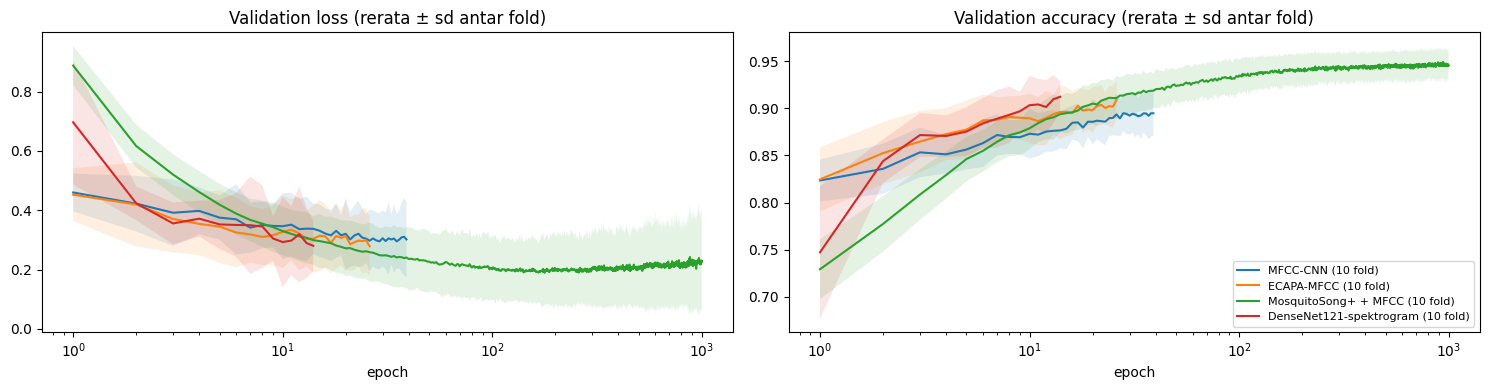

In [25]:
# Kurva validasi rata-rata per keluarga (varian terpilih per fold)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for fam in ACTIVE:
    H = [pd.read_csv(f'{fold_dir(x, f)}/history.csv') for f in range(10) if (x := selected_exp(fam, f))]
    if not H:
        continue
    n_ep = min(len(h) for h in H); ep = np.arange(1, n_ep + 1)
    for a, col in zip(axes, ('val_loss', 'val_acc')):
        v = np.stack([h[col].values[:n_ep] for h in H]); a.plot(ep, v.mean(0), label=f'{LBL(fam)} ({len(H)} fold)')
        a.fill_between(ep, v.mean(0) - v.std(0), v.mean(0) + v.std(0), alpha=.12)
axes[0].set(title='Validation loss (rerata ± sd antar fold)', xlabel='epoch', xscale='log')
axes[1].set(title='Validation accuracy (rerata ± sd antar fold)', xlabel='epoch', xscale='log'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/02_kurva_validasi.png', dpi=150); plt.show()

## 8. Artefak dan Batasan

`runs/<run>/fold<k>/` menyimpan bobot, histori, prediksi test dan validation, serta konfigurasi per fold. Nama run = model + tag (`mfcc_cnn_lr1e-3`, `densenet121_lr3e-4`, `densenet121_asp_sel`, `<keluarga>_s1`, ...). `figures/` berisi tabel dan gambar; semuanya beserta `requirements.txt` dikemas ke `results.zip`.

- Pemilihan set model sudah melihat hasil validation run pertama (6 fold). Model final dilatih ulang dari awal dengan konfigurasi baru; ini dicatat sebagai keterbatasan.
- Pembanding resep cepat dan fine-tune memakai dua lr; MosquitoSong+ memakai satu resep penulis. Ini sengaja: baseline memakai konfigurasi terkuat yang diketahui (resep cepat justru menurunkan MS+ ke MF1 0,884 di run pertama).
- Job yang dilanjutkan dari checkpoint tidak bit-identik dengan run tanpa jeda (urutan acak dropout/shuffle TF tidak disimpan), tetapi state RNG augmentasi, optimizer, dan histori dipulihkan.
- DenseNet121 ±20× lebih besar dari MosquitoSong+; parameter dan latensi dibandingkan di notebook 03.

In [26]:
# Ekspor lingkungan (requirements) dan kemas semua artefak
import subprocess, zipfile
with open('requirements.txt', 'w') as f:
    f.write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
with zipfile.ZipFile('results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for pat in ('figures/*', 'logs/*', 'runs/*/fold*/*', 'mosq_lib.py', 'requirements.txt'):
        for f in glob.glob(pat):
            if os.path.isfile(f):
                z.write(f)
print(f"results.zip: {os.path.getsize('results.zip')/1e6:.1f} MB | requirements.txt: "
      f"{sum(1 for _ in open('requirements.txt'))} paket")

results.zip: 4085.2 MB | requirements.txt: 936 paket
